# CPSC 6440 01 / AMTH 3220 01 / CPSC 4844 01 / MATH 5220 01 / MATH 7440 01 - Problem Set 2

# Instructions:
- Run each cell in sequence.
- Fill in the missing parts (marked as TODO).
- Test your implementation using the toy datasets provided.


# PHATE Regularized Autoencoder + Neural ODE Model

In [1]:
!pip install POT torchdiffeq scanpy phate gdown pandas==2.2.0

## Step 1: Import Required Libraries

Import all necessary libraries for building and training the PHATE regularized autoencoder, including PyTorch for neural networks, scikit-learn for data preprocessing, and scanpy for handling single-cell data.

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from tqdm import tqdm
import phate
import scipy
import scanpy as sc
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics.pairwise import pairwise_distances
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from typing import List, Union, Optional, Tuple
import ot
import gdown
from torchdiffeq import odeint
import numpy as np
from tqdm import tqdm

/Users/annasu/miniconda3/envs/cpsc6440/lib/python3.12/site-packages/scanpy/_utils/__init__.py:33: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/Users/annasu/miniconda3/envs/cpsc6440/lib/python3.12/site-packages/scanpy/__init__.py:24: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/Users/annasu/miniconda3/envs/cpsc6440/lib/python3.12/site-packages/scanpy/readwrite.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):


## Step 2: Load the Embryoid Body Dataset

Load the preprocessed single-cell RNA-seq data from the Embryoid Body dataset. This dataset contains gene expression data across different time points during embryonic development, with precomputed PCA and PHATE embeddings. Inspect the loaded AnnData object to understand the data dimensions, available embeddings (PCA, PHATE), and metadata (time labels).

In [3]:
file_id_adata = "15O_2v3q6W5XdUfrlC3j-gcs9S-Rw0Re3"

url_adata = f"https://drive.google.com/uc?id={file_id_adata}"

output_data = "adata_time.h5ad"

gdown.download(url_adata, output_data, quiet=False)

print("Download complete!")


Downloading...
From (original): https://drive.google.com/uc?id=15O_2v3q6W5XdUfrlC3j-gcs9S-Rw0Re3
From (redirected): https://drive.google.com/uc?id=15O_2v3q6W5XdUfrlC3j-gcs9S-Rw0Re3&confirm=t&uuid=95c48b4e-4261-49fd-b2b9-e89d823f81eb
To: /Users/annasu/Library/CloudStorage/OneDrive-YaleUniversity/Year 4/Classes/CPSC 6440/HW/PS2/adata_time.h5ad
100%|██████████| 353M/353M [00:14<00:00, 24.4MB/s] 

Download complete!


In [4]:
adata = sc.read_h5ad('adata_time.h5ad')

In [5]:
adata

AnnData object with n_obs × n_vars = 17944 × 18019
    obs: 'time_label', 'pseudotime'
    uns: 'pca'
    obsm: 'X_pca', 'X_phate'
    varm: 'PCs'

## Step 3: Create Custom Dataset Class

Define a PyTorch Dataset class that handles PCA data as input and uses precomputed PHATE distances for regularization. This class will:
- Extract PCA embeddings from the AnnData object
- Normalize the data if requested
- Precompute pairwise distances in PHATE space
- Provide batched data for training with corresponding PHATE distance information

In [6]:
class PhateDataset(Dataset):
    """
    Dataset class for PHATE regularized autoencoder training.
    Includes PCA data and precomputed PHATE distances.
    """
    def __init__(self, adata, batch_size=256, normalize=True):
        """
        Args:
            adata: AnnData object with obsm['X_pca'] (PCA data) and obsm['X_phate'] (PHATE embedding)
            batch_size: Size of batches for pairwise distance computation
            normalize: Whether to normalize the PCA data
        """
        # Extract PCA data instead of raw gene expression
        self.X = adata.obsm['X_pca'].astype(np.float32)

        # Normalize if requested
        if normalize:
            scaler = StandardScaler()
            self.X = scaler.fit_transform(self.X).astype(np.float32)

        # Extract PHATE embedding
        self.X_phate = adata.obsm['X_phate'].astype(np.float32)

        # Normalize PHATE embedding if requested
        if normalize:
            scaler_phate = StandardScaler()
            self.X_phate = scaler_phate.fit_transform(self.X_phate).astype(np.float32)

        # Precompute pairwise distances in PHATE space
        print("Computing pairwise PHATE distances...")
        self.phate_distances = pairwise_distances(self.X_phate, metric='euclidean').astype(np.float32)

        self.n_samples = self.X.shape[0]
        self.batch_size = batch_size

        print(f"Dataset initialized with {self.n_samples} samples")
        print(f"PCA data shape: {self.X.shape}")
        print(f"PHATE embedding shape: {self.X_phate.shape}")
        print(f"PHATE distance matrix shape: {self.phate_distances.shape}")

    def __len__(self):
        # Number of batches we can create
        return (self.n_samples + self.batch_size - 1) // self.batch_size

    def __getitem__(self, idx):
        """
        Get a batch of data with corresponding PHATE distances
        """
        start_idx = idx * self.batch_size
        end_idx = min(start_idx + self.batch_size, self.n_samples)

        # Get batch indices
        batch_indices = np.arange(start_idx, end_idx)

        # Get batch data
        batch_x = torch.from_numpy(self.X[batch_indices])

        # Get pairwise distances for this batch
        batch_distances = self.phate_distances[np.ix_(batch_indices, batch_indices)]
        # Convert distance matrix to vector format (upper triangular)
        batch_distances_vec = torch.from_numpy(batch_distances[np.triu_indices(len(batch_indices), k=1)])

        return {
            'x': batch_x,
            'd': batch_distances_vec,
            'indices': torch.from_numpy(batch_indices.astype(np.int64))
        }

## Step 4: Define the Autoencoder Architecture

Create a PyTorch autoencoder model with:
- An encoder that maps PCA space to a lower-dimensional latent space
- A decoder that reconstructs the PCA representation from the latent space
- Configurable hidden layer dimensions for flexibility

Your task is to build the encoder and decoder i.e to fill in the TODOs as specified in the code cell below.

In [7]:
class Autoencoder(nn.Module):
    """
    Simple autoencoder for dimensionality reduction with distance preservation.
    """
    def __init__(
        self,
        input_dim: int,
        latent_dim: int,
        hidden_dims: List[int] = [128, 64]
    ):
        super().__init__()

        self.input_dim = input_dim
        self.latent_dim = latent_dim

        # TODO: Build an encoder consisting of linear layers with activation functions in between with input_dim and
        # hidden_dim specified in the function call. Recall the last encoder layer should contain the latent_dim.
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dims[0]),
            nn.ReLU(),
            nn.Linear(hidden_dims[0], hidden_dims[1]),
            nn.ReLU(),
            nn.Linear(hidden_dims[1], latent_dim)
        )

        # TODO: Build a decoder consisting of linear layers with activation functions in between with input_dim and
        # hidden_dim specified in the function call.
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dims[1]),
            nn.ReLU(),
            nn.Linear(hidden_dims[1], hidden_dims[0]),
            nn.ReLU(),
            nn.Linear(hidden_dims[0], input_dim)
        )


    def encode(self, x):
        """Encode input to latent space"""
        return self.encoder(x)

    def decode(self, z):
        """Decode from latent space to input space"""
        return self.decoder(z)

    def forward(self, x):
        """Full forward pass"""
        z = self.encode(x)
        return self.decode(z)

## Step 5: Define PHATE Regularized Training Function

Implement the training function that combines:
- **Reconstruction loss**: Ensures the autoencoder can reconstruct the PCA input
- **PHATE distance preservation loss**: Ensures that distances in the latent space preserve the PHATE manifold structure

Your task is to fill in the TODOs as listed inside this training function.

In [8]:
def train_phate_autoencoder(
    model,
    dataset,
    num_epochs,
    learning_rate,
    device,
    recon_weight,
    phate_weight,
    validation_split):
    """
    Train autoencoder with PHATE distance regularization.

    Args:
        model: The autoencoder model
        dataset: PhateDataset containing gene expression and PHATE distances
        num_epochs: Number of training epochs
        learning_rate: Learning rate for optimizer
        device: Device to train on
        recon_weight: Weight for reconstruction loss
        phate_weight: Weight for PHATE distance preservation loss
        validation_split: Fraction of data to use for validation

    Returns:
        Training history dictionary
    """
    # TODO: Initialize model, optimizer (Use the Adam optimizer), and loss function (MSELoss)
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    mse_loss_fn = nn.MSELoss()

    # Create train/validation split
    total_batches = len(dataset)
    val_batches = int(total_batches * validation_split)
    train_batches = total_batches - val_batches

    # Create data loaders
    train_loader = DataLoader(
        torch.utils.data.Subset(dataset, range(train_batches)),
        batch_size=1,
        shuffle=True
    )
    val_loader = DataLoader(
        torch.utils.data.Subset(dataset, range(train_batches, total_batches)),
        batch_size=1,
        shuffle=False
    ) if val_batches > 0 else None

    history = {
        'train_loss': [],
        'val_loss': [],
        'recon_loss': [],
        'phate_loss': []
    }

    print(f'Training PHATE Autoencoder on device: {device}')
    print(f'Reconstruction weight: {recon_weight}, PHATE weight: {phate_weight}')
    print(f'Train batches: {train_batches}, Validation batches: {val_batches}')

    for epoch in tqdm(range(num_epochs), desc='Epochs'):
        # Training phase
        model.train()
        train_loss = 0.0
        recon_loss_sum = 0.0
        phate_loss_sum = 0.0

        for batch in train_loader:
            data = batch['x'].squeeze(0).to(device)  # Remove batch dimension added by DataLoader
            phate_distances = batch['d'].squeeze(0).to(device)

            # TODO: Zero the gradients
            optimizer.zero_grad()

            # TODO: Forward pass through the model to get embeddings and reconstructions
            embeddings = model.encode(data)
            reconstructions = model.decode(embeddings)

            # TODO: Compute reconstruction loss
            recon_loss = mse_loss_fn(reconstructions, data)

            # TODO: Compute PHATE distance preservation loss: compute pairwise distances in latent space
            # and compare to PHATE distances
            latent_dists = torch.pdist(embeddings, p=2)  # pairwise Euclidean distances between latent embeddings, gives a [n, n] distance matrix
            phate_loss = mse_loss_fn(latent_dists, phate_distances) 

            # TODO: Now compute the combined loss which includes both reconstruction and PHATE losses
            # with some weights on each.
            loss = recon_weight * recon_loss + phate_weight * phate_loss
            
            # TODO: Backpropagate and update model parameters
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            recon_loss_sum += recon_loss.item()
            phate_loss_sum += phate_loss.item()

        # Average losses
        avg_train_loss = train_loss / len(train_loader)
        avg_recon_loss = recon_loss_sum / len(train_loader)
        avg_phate_loss = phate_loss_sum / len(train_loader)

        history['train_loss'].append(avg_train_loss)
        history['recon_loss'].append(avg_recon_loss)
        history['phate_loss'].append(avg_phate_loss)

        # Validation phase
        if val_loader is not None:
            model.eval()
            val_loss = 0.0
            val_recon_loss_sum = 0.0
            val_phate_loss_sum = 0.0

            with torch.no_grad():
                for batch in val_loader:
                    data = batch['x'].squeeze(0).to(device)
                    phate_distances = batch['d'].squeeze(0).to(device)

                    # TODO: Forward pass through the model to get embeddings and reconstructions
                    embeddings = model.encode(data)
                    reconstructions = model.decode(embeddings)

                    # TODO: Compute reconstruction loss
                    recon_loss = mse_loss_fn(reconstructions, data) 

                    # TODO: Compute PHATE distance preservation loss: compute pairwise distances in latent space
                    # and compare to PHATE distances
                    latent_dists = torch.pdist(embeddings, p=2)  # pairwise Euclidean distances between latent embeddings, gives a [n, n] distance matrix
                    phate_loss = mse_loss_fn(latent_dists, phate_distances) 

                    # TODO: Now compute the combined loss which includes both reconstruction and PHATE losses
                    # with some weights on each.
                    loss = recon_weight * recon_loss + phate_weight * phate_loss

                    val_loss += loss.item()
                    val_recon_loss_sum += recon_loss.item()
                    val_phate_loss_sum += phate_loss.item()

            avg_val_loss = val_loss / len(val_loader)
            history['val_loss'].append(avg_val_loss)

            if epoch % 10 == 0:  # Print every 10 epochs
                tqdm.write(f'Epoch {epoch+1:3d}: Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}, '
                          f'Recon: {avg_recon_loss:.4f}, PHATE: {avg_phate_loss:.4f}')
        else:
            if epoch % 10 == 0:
                tqdm.write(f'Epoch {epoch+1:3d}: Train Loss: {avg_train_loss:.4f}, '
                          f'Recon: {avg_recon_loss:.4f}, PHATE: {avg_phate_loss:.4f}')

    return history

## Step 6: Create Dataset Instance

Initialize the PhateDataset with the loaded data, using PCA embeddings as input and PHATE distances for regularization.

In [9]:
# Create new dataset with PCA data
print("Creating PHATE dataset with PCA input...")
phate_dataset_pca = PhateDataset(adata, batch_size=1024, normalize=True)

Creating PHATE dataset with PCA input...
Computing pairwise PHATE distances...
Dataset initialized with 17944 samples
PCA data shape: (17944, 50)
PHATE embedding shape: (17944, 2)
PHATE distance matrix shape: (17944, 17944)


## Step 7: Configure and Initialize the Autoencoder Model

Create the autoencoder with appropriate dimensions:
- Input dimension matches PCA components (50)
- Smaller latent dimension (2) for visualization compatibility with PHATE
- Hidden layers sized appropriately for the reduced input space

Your task is to fill in the TODOs as listed below

In [10]:

# Create new autoencoder model for PCA input
input_dim = adata.obsm['X_pca'].shape[1]
latent_dim = 2
hidden_dims = [32, 32, 32]

# TODO: Initialize autoencoder with PCA input
model_pca = Autoencoder(input_dim=input_dim, latent_dim=latent_dim, hidden_dims=hidden_dims)

# You may print the model summary here to verify
total_params = sum(p.numel() for p in model_pca.parameters())
print(f"Total parameters: {total_params:,}")
print(f"Model architecture:")
print(model_pca)

Total parameters: 5,556
Model architecture:
Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=50, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=50, bias=True)
  )
)


## Step 8: Train the PHATE Regularized Autoencoder

Execute the training process with:
- Higher number of epochs for convergence
- Balanced weights between reconstruction and PHATE distance preservation
- Monitoring of both loss components during training

Your task is to fill in the TODOs as listed below

In [11]:
# Train the PHATE regularized autoencoder with PCA input
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# Training hyperparameters
num_epochs = 500
learning_rate = 1e-2
recon_weight = 0.01
phate_weight = 1.0  # Higher weight since we have fewer parameters

# TODO: Call the training function with appropriate arguments and return the training history
history_pca = train_phate_autoencoder(
    model=model_pca,
    dataset=phate_dataset_pca,
    num_epochs=num_epochs,
    learning_rate=learning_rate,
    device=device,
    recon_weight=recon_weight,
    phate_weight=phate_weight,
    validation_split=0.1
)


Using device: cpu
Training PHATE Autoencoder on device: cpu
Reconstruction weight: 0.01, PHATE weight: 1.0
Train batches: 17, Validation batches: 1


Epochs:   0%|          | 1/500 [00:00<02:27,  3.38it/s]

Epoch   1: Train Loss: 1.2241, Val Loss: 0.6055, Recon: 0.9981, PHATE: 1.2141


Epochs:   2%|▏         | 11/500 [00:03<02:20,  3.48it/s]

Epoch  11: Train Loss: 0.1074, Val Loss: 0.0911, Recon: 0.9042, PHATE: 0.0984


...

Epochs:  96%|█████████▌| 481/500 [02:14<00:05,  3.71it/s]

Epoch 481: Train Loss: 0.0290, Val Loss: 0.0442, Recon: 0.8349, PHATE: 0.0206


Epochs:  98%|█████████▊| 491/500 [02:17<00:02,  3.69it/s]

Epoch 491: Train Loss: 0.0484, Val Loss: 0.0459, Recon: 0.8751, PHATE: 0.0397


Epochs: 100%|██████████| 500/500 [02:20<00:00,  3.57it/s]


## Step 9: Visualize Training Progress

Plot the training history to analyze:
- Total loss convergence
- Individual contribution of reconstruction vs PHATE distance losses
- Validation performance if available

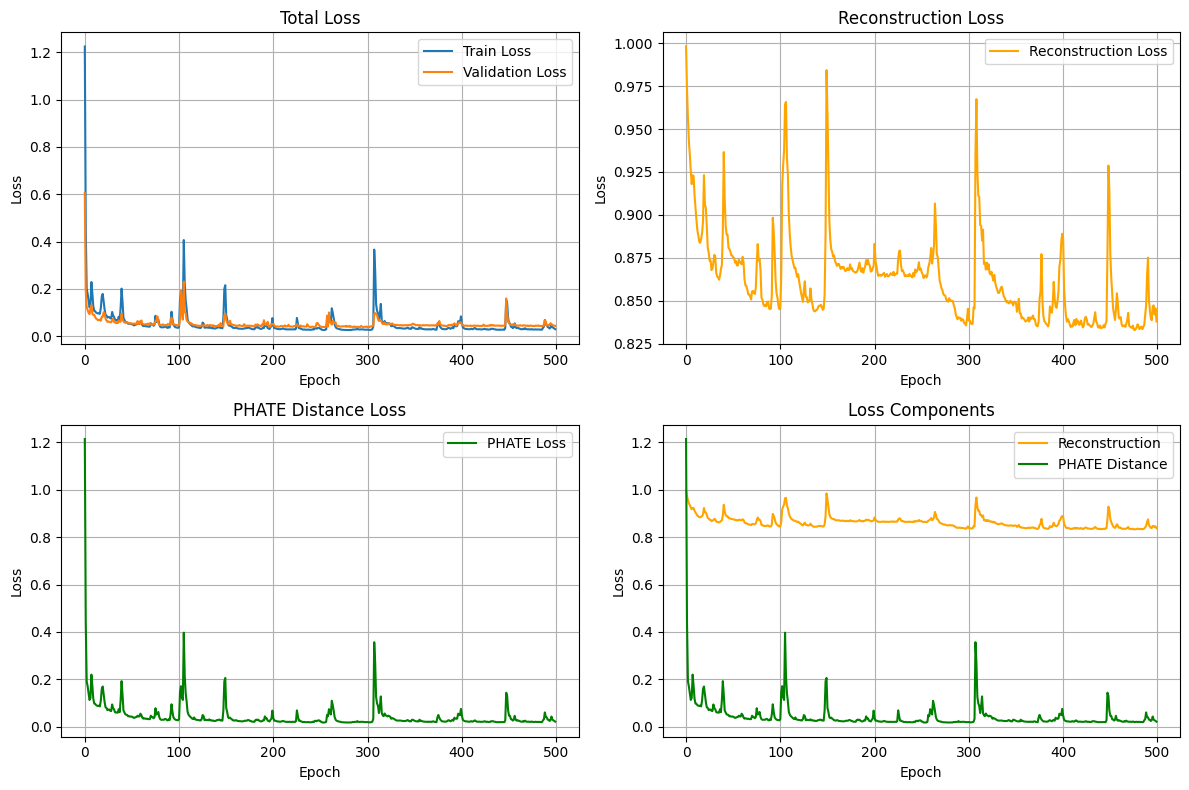

Final training loss: 0.0302
Final reconstruction loss: 0.8378
Final PHATE loss: 0.0218
Final validation loss: 0.0443


In [12]:
# Visualize training history
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Plot training and validation loss
axes[0, 0].plot(history_pca['train_loss'], label='Train Loss')
if history_pca['val_loss']:
    axes[0, 0].plot(history_pca['val_loss'], label='Validation Loss')
axes[0, 0].set_title('Total Loss')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True)

# Plot reconstruction loss
axes[0, 1].plot(history_pca['recon_loss'], label='Reconstruction Loss', color='orange')
axes[0, 1].set_title('Reconstruction Loss')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Loss')
axes[0, 1].legend()
axes[0, 1].grid(True)

# Plot PHATE loss
axes[1, 0].plot(history_pca['phate_loss'], label='PHATE Loss', color='green')
axes[1, 0].set_title('PHATE Distance Loss')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Loss')
axes[1, 0].legend()
axes[1, 0].grid(True)

# Plot loss components
axes[1, 1].plot(history_pca['recon_loss'], label='Reconstruction', color='orange')
axes[1, 1].plot(history_pca['phate_loss'], label='PHATE Distance', color='green')
axes[1, 1].set_title('Loss Components')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Loss')
axes[1, 1].legend()
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

print(f"Final training loss: {history_pca['train_loss'][-1]:.4f}")
print(f"Final reconstruction loss: {history_pca['recon_loss'][-1]:.4f}")
print(f"Final PHATE loss: {history_pca['phate_loss'][-1]:.4f}")
if history_pca['val_loss']:
    print(f"Final validation loss: {history_pca['val_loss'][-1]:.4f}")

Explanation for Reconstruction loss being much higher (Siddharth): recon_weight = 0.01
phate_weight = 1.0

## Step 10: Generate Latent Embeddings

Use the trained autoencoder to:
- Encode all PCA data into the latent space
- Generate reconstructions to assess quality
- Store the latent embeddings for visualization and analysis

In [13]:
# Generate latent embeddings using the trained autoencoder
model_pca.eval()
device = next(model_pca.parameters()).device

# Get PCA data
pca_data = torch.from_numpy(phate_dataset_pca.X).to(device)

# TODO: Generate latent embeddings as latent_embeddings by calling the encode method of the trained model
latent_embeddings = model_pca.encode(pca_data).detach().cpu().numpy()

# Store embeddings in adata for comparison
adata.obsm['X_phate_ae'] = latent_embeddings

The autoencoder embedding and the original PHATE embedding should look almost identical — the model preserves the PHATE manifold structure very well, so the autoencoder is working as intended!

## Step 11: Analyze Time Point Structure

Visualize the autoencoder embedding colored by discrete time labels to understand how well it captures temporal structure.

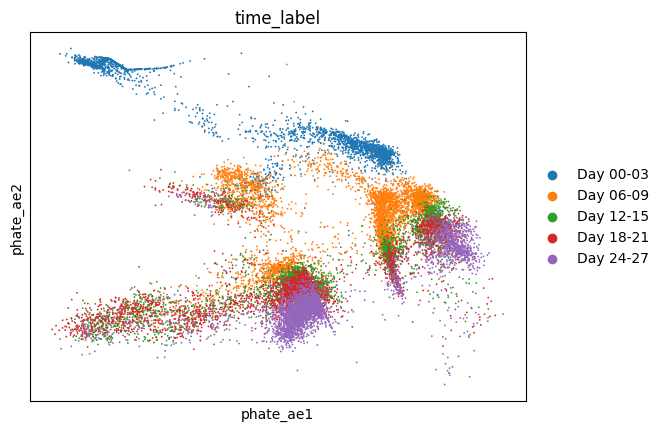

In [14]:
sc.pl.embedding(adata, basis='phate_ae', color=['time_label'])

## Step 12: Create Numeric Time Bins

Convert categorical time labels to numeric values for easier analysis and visualization of temporal progression. Plot the autoencoder embedding colored by the numeric time bins to see the temporal progression more clearly.

In [15]:
adata.obs['time_bin'] = adata.obs['time_label'].map({
    'Day 00-03': 0.,
    'Day 06-09': 1.,
    'Day 12-15': 2.,
    'Day 18-21': 3.,
    'Day 24-27': 4.,
})

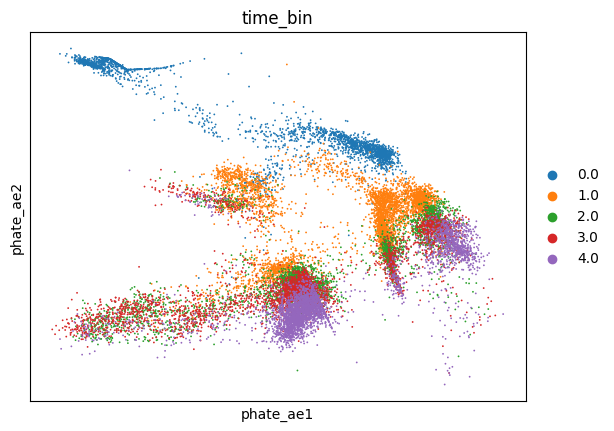

In [16]:
sc.pl.embedding(adata, basis='phate_ae', color=['time_bin'])

## Step 13: Implement the Neural ODE model - Continuous Normalizing Flows

This section implements the Neural ODE model, which learns continuous dynamics using Neural ODEs to model developmental trajectories. The implementation includes:

- **ODEFunc**: Neural network $f_\theta(x_t, t)$ that defines the vector field (dx/dt)
- **Loss functions**:
  - Optimal transport loss for matching distributions:  

  $$
  \mathcal{L}_{\mathrm{OT}} := \sum_{i=1}^{T-1} W_2(\hat{\mu}_i, \mu_i),
  \quad \text{where }
  W_{2}^{2}(\mu, \nu) = \inf_{\pi \in \Pi(\mu, \nu)} \int d(x, y) \, d\pi(x, y)
  $$

- Density loss for maintaining neighborhood structure:  

$$
\mathcal{L}_{d} := \sum_{t=1}^{T-1} \sum_{x \in \hat{X}_t} \ell_{\mathrm{density}},
\quad \text{where }
\ell_{\text{density}}(x, t) = \frac{1}{k} \sum_{j=1}^{k} \max \big(0,\, d_{(j)}(x(t)) - h \big)
$$
  - Energy loss for regularizing the flow smoothness:
    \begin{equation}
    \mathcal{L}_{e} := \frac{1}{n} \sum_{x_t \in \hat{X}_t} \sum_{i=1}^{T-1} \int_{i-1}^{i} \| f_\theta(x_t, t) \|_2^2 \, dt
    \end{equation}

The final loss function should look like:
\begin{equation}
\mathcal{L} = \lambda_{e}\mathcal{L}_{e} + \lambda_{\mathrm{OT}}\mathcal{L}_{\mathrm{OT}} + \lambda_{d}\mathcal{L}_{d}
\end{equation}

Your task is to implement the OT loss, density loss, and energy loss as directed in the TODOs below.

In [36]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import ot
from torchdiffeq import odeint
import numpy as np
from tqdm import tqdm
from typing import List, Dict, Tuple

class ODEFunc(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim + 1, hidden_dim), # additional dim for time t.
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, input_dim),
        )

    def forward(self, t, x):
        # t is scalar, x is [batch_size, input_dim]
        # Expand t to [batch_size, 1] to match x's batch dimension
        t_expanded = t.expand(x.size(0), 1)
        input = torch.cat([t_expanded, x], dim=-1)
        return self.model(input)

def ot_loss(source, target):
    # TODO: Implement optimal transport loss using POT library
    # Use the Python OT library to compute μ, ν and the 2-Wasserstein distance 
    # (emd2 module) and PyTorch to compute the Euclidean ground cost.

    source = source.detach().cpu().numpy()
    target = target.detach().cpu().numpy()
    n_source = source.shape[0]
    n_target = target.shape[0]
    # Uniform weights
    mu = np.ones((n_source,), dtype=np.float64) / float(n_source)
    nv = np.ones((n_target,), dtype=np.float64) / float(n_target)
    # Compute squared Euclidean ground-cost matrix
    M = ot.dist(source, target) ** 2
    # Earth Mover's Distance squared (scalar)
    w2 = ot.emd2(mu, nv, M)
    return torch.tensor(w2, dtype=torch.float32)


def energy_loss(model, x0, t_seq):
    """
    Compute energy loss by evaluating vector field magnitude along the ODE trajectory.
    This penalizes large vector field values to encourage smoother flows.

    Args:
        model: ODEFunc model
        x0: Initial points [batch_size, input_dim]
        t_seq: Time sequence [num_times]

    Returns:
        Energy loss (mean squared magnitude of vector field along trajectory)
    """
    # TODO: Implement energy loss computation
    # TODO: Compute the full trajectory (Hint: use odeint)
    trajectory = odeint(model, x0, t_seq)  # Shape: [num_times, batch_size, input_dim]
    energy_loss = torch.zeros(1, device=x0.device, dtype=x0.dtype)

    # TODO: Evaluate vector field at each point along the trajectory
    for i, t_val in enumerate(t_seq):
        # TODO: Current points at time t_val: trajectory[i]
        x_t = trajectory[i]  # Shape: [batch_size, input_dim]

        # TODO: Create time tensor for all batch points
        time_tensor = t_val * torch.ones(x_t.size(0), 1).to(x_t.device, dtype=x_t.dtype)

        # TODO: Get vector field (dx/dt) at current trajectory points
        vector_field = model(time_tensor, x_t)  # dx/dt evaluated at (t_val, x_t)

        # TODO: Add squared magnitude (L2 norm squared for each point)
        energy_loss += (vector_field ** 2).mean()

    # TODO: Return average energy across all trajectory evaluations
    return energy_loss / len(t_seq)
    
def density_loss(source, target, top_k=5, hinge_value=0.1):
    """
    Density loss that encourages points to be close to target distribution.
    Uses hinge loss on k-nearest neighbor distances.
    """
    # TODO: Implement density loss using hinge loss on k-nearest neighbor distances
    # Compute pairwise distances from each source point to all target points
    # result shape: [n_source, n_target]
    dists = torch.cdist(source, target, p=2)
    # k = min(top_k, dists.size(1))
    knn_vals, _ = torch.topk(dists, k=top_k, largest=False)
    hinge = torch.clamp(knn_vals - hinge_value, min=0.0)
    loss = hinge.mean()
    return loss


def infer(x0, model, t_seq):
    return odeint(model, x0, t_seq)


class TimeSeriesDataset(Dataset):
    """
    Dataset for time series data with variable number of points per time step.
    Data format: list of (X_t, t) tuples, where X_t has shape [n_points, dim]
    """
    def __init__(self, time_series_data: List[Tuple[np.ndarray, float]]):
        """
        Args:
            time_series_data: List of (X_t, t) tuples, where X_t is [n_points, dim] array
        """
        self.time_series_data = time_series_data
        self.times = [t for _, t in time_series_data]

    def __len__(self):
        return len(self.time_series_data) - 1  # Number of intervals

    def __getitem__(self, idx):
        """
        Returns data for training interval idx -> idx+1
        """
        X_t, t_start = self.time_series_data[idx]
        X_t1, t_end = self.time_series_data[idx + 1]

        return {
            'X_start': torch.tensor(X_t, dtype=torch.float32),
            'X_end': torch.tensor(X_t1, dtype=torch.float32),
            't_start': t_start,
            't_end': t_end,
            'interval_idx': idx
        }

    def get_time_sequence(self, start_idx=0, end_idx=None):
        """Get time sequence from start_idx to end_idx"""
        if end_idx is None:
            end_idx = len(self.times)
        return torch.tensor(self.times[start_idx:end_idx], dtype=torch.float32)

    def get_initial_condition(self, start_idx=0):
        """Get initial condition X_0"""
        X_0, _ = self.time_series_data[start_idx]
        return torch.tensor(X_0, dtype=torch.float32)


def train_mioflow(
    model: ODEFunc,
    dataset: TimeSeriesDataset,
    num_epochs: int,
    mode: str = 'local',  # 'local' or 'global'
    batch_size: int = None,  # For local mode, how many points to sample per time step
    learning_rate: float = 1e-3,
    device: str = "cuda" if torch.cuda.is_available() else "cpu",
    lambda_ot: float = 1.0,
    lambda_density: float = 0.1,
    lambda_energy: float = 0.01,
    energy_time_steps: int = 10
) -> Dict:
    """
    Train MioFlow model.

    Args:
        model: ODEFunc model
        dataset: TimeSeriesDataset
        num_epochs: Number of training epochs
        mode: 'local' (train each interval) or 'global' (train full trajectory)
        batch_size: For local mode, number of points to sample per time step (None = use all)
        learning_rate: Learning rate
        device: Device to train on
        lambda_ot: Weight for OT loss
        lambda_density: Weight for density loss
        lambda_energy: Weight for energy regularization
        energy_time_steps: Number of time steps for energy evaluation

    Returns:
        Training history
    """
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    history = {
        'epoch': [],
        'total_loss': [],
        'ot_loss': [],
        'density_loss': [],
        'energy_loss': []
    }

    epoch_pbar = tqdm(range(num_epochs), desc='Epochs')
    for epoch in epoch_pbar:
        epoch_losses = {'total': 0.0, 'ot': 0.0, 'density': 0.0, 'energy': 0.0}
        num_batches = 0

        if mode == 'local':
            # Local mode: train each time interval separately
            for interval_idx in range(len(dataset)):
                batch = dataset[interval_idx]

                X_start = batch['X_start'].to(device)
                X_end = batch['X_end'].to(device)
                t_start = batch['t_start']
                t_end = batch['t_end']

                # Sample points if batch_size specified
                if batch_size is not None:
                    min_size = min(X_start.size(0), X_end.size(0))
                    effective_batch_size = min(batch_size, min_size)
                    indices = torch.randperm(min_size)[:effective_batch_size]
                    X_start = X_start[indices]
                    X_end = X_end[indices]

                # Integrate from X_start to predict X_end
                t_interval = torch.tensor([t_start, t_end], device=device, dtype=torch.float32)
                X_pred = odeint(model, X_start, t_interval)[1]  # Get final time point

                # Compute losses
                ot_loss_val = ot_loss(X_pred, X_end)
                density_loss_val = density_loss(X_pred, X_end)
                energy_loss_val = energy_loss(model, X_start, t_interval)

                # Total loss
                total_loss = (lambda_ot * ot_loss_val +
                            lambda_density * density_loss_val +
                            lambda_energy * energy_loss_val)

                # Optimize
                optimizer.zero_grad()
                total_loss.backward()
                optimizer.step()

                # Accumulate losses
                epoch_losses['total'] += total_loss.item()
                epoch_losses['ot'] += ot_loss_val.item()
                epoch_losses['density'] += density_loss_val.item()
                epoch_losses['energy'] += energy_loss_val.item()
                num_batches += 1

        elif mode == 'global':
            # Global mode: train full trajectory from X_0
            X_0 = dataset.get_initial_condition().to(device)
            full_t_seq = dataset.get_time_sequence().to(device)

            # Integrate full trajectory
            trajectory = odeint(model, X_0, full_t_seq)

            # Compare with ground truth at each time step
            total_loss = 0.0
            ot_loss_total = 0.0
            density_loss_total = 0.0

            for i in range(1, len(full_t_seq)):  # Skip t=0 (initial condition)
                X_pred = trajectory[i]
                X_true, _ = dataset.time_series_data[i]
                X_true = torch.tensor(X_true, device=device, dtype=torch.float32)

                # Sample if needed
                if batch_size is not None and X_pred.size(0) > batch_size:
                    indices = torch.randperm(X_pred.size(0))[:batch_size]
                    X_pred = X_pred[indices]
                    X_true = X_true[indices]

                ot_loss_val = ot_loss(X_pred, X_true)
                density_loss_val = density_loss(X_pred, X_true)
                total_loss += ot_loss_val + lambda_density * density_loss_val
                ot_loss_total += ot_loss_val.item()
                density_loss_total += density_loss_val.item()

            # Energy loss on full trajectory
            energy_t_seq = torch.linspace(full_t_seq[0], full_t_seq[-1], energy_time_steps, device=device)
            energy_loss_val = energy_loss(model, X_0, energy_t_seq)

            total_loss += lambda_energy * energy_loss_val

            # Optimize
            optimizer.zero_grad()
            total_loss.backward()
            optimizer.step()

            # Record losses
            epoch_losses['total'] += total_loss.item()
            epoch_losses['ot'] += ot_loss_total
            epoch_losses['density'] += density_loss_total
            epoch_losses['energy'] += energy_loss_val.item()
            num_batches = 1

        else:
            raise ValueError(f"Unknown mode: {mode}")

        # Average losses
        for key in epoch_losses:
            epoch_losses[key] /= num_batches

        # Record history
        history['epoch'].append(epoch + 1)
        history['total_loss'].append(epoch_losses['total'])
        history['ot_loss'].append(epoch_losses['ot'])
        history['density_loss'].append(epoch_losses['density'])
        history['energy_loss'].append(epoch_losses['energy'])

        # Update progress bar with loss information
        epoch_pbar.set_postfix({
            'Total': f'{epoch_losses["total"]:.4f}',
            'OT': f'{epoch_losses["ot"]:.4f}',
            'Density': f'{epoch_losses["density"]:.4f}',
            'Energy': f'{epoch_losses["energy"]:.4f}'
        })

    return history



## Step 14: Prepare Time Series Data

Create a TimeSeriesDataset from the autoencoder embeddings, organizing data by time bins for training the continuous flow model.

In [18]:
mioflow_data = TimeSeriesDataset(
    [(adata.obsm['X_phate_ae'][adata.obs['time_bin'] == i], i) for i in np.unique(adata.obs['time_bin'])]
)

## Step 15: Train the Neural ODE Model

Train the Neural ODE model to learn the continuous dynamics between time points in the autoencoder latent space.

In [37]:
# TODO: Initialize ODEFunc model with input_dim = 2 and hidden_dim = 32 and train using train_mioflow function
# returning the training history as `history` for further visualization.
mioflow_model = ODEFunc(input_dim=2, hidden_dim=32)
history = train_mioflow(
    model=mioflow_model,
    dataset=mioflow_data,
    num_epochs=200,
    mode='local',
    batch_size=256,
    learning_rate=1e-3,
    device=device,
    lambda_ot=1.0,
    lambda_density=0.1,
    lambda_energy=0.01,
    energy_time_steps=10
)

Epochs: 100%|██████████| 200/200 [00:34<00:00,  5.76it/s, Total=0.6065, OT=0.6012, Density=0.0231, Energy=0.3018]


## Step 16: Visualize MioFlow Training Progress

Plot the training losses to monitor convergence of the different loss components in the MioFlow training.

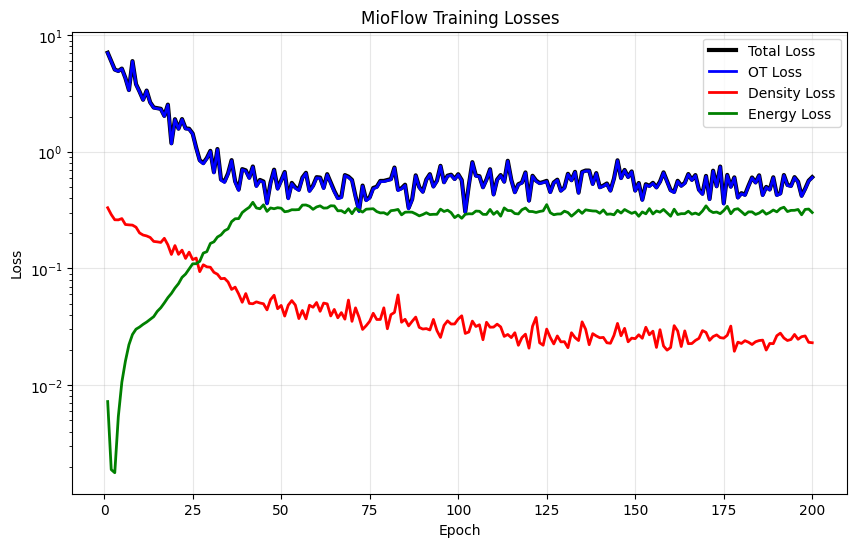

In [38]:
epochs = history['epoch']

plt.figure(figsize=(10, 6))
plt.plot(epochs, history['total_loss'], 'k-', linewidth=3, label='Total Loss')
plt.plot(epochs, history['ot_loss'], 'b-', linewidth=2, label='OT Loss')
plt.plot(epochs, history['density_loss'], 'r-', linewidth=2, label='Density Loss')
plt.plot(epochs, history['energy_loss'], 'g-', linewidth=2, label='Energy Loss')

plt.title('MioFlow Training Losses')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.yscale('log')  # Optional: log scale for better visualization
plt.show()

Explanation for the increasing energy loss (Siddharth):
Don't want to penalize the energy loss as mush as ot and density loss

In [39]:
# Final density loss
print(f"Final Density Loss: {history['density_loss'][-1]:.4f}")

Final Density Loss: 0.0231


## Step 17: Generate Continuous Trajectories

Use the trained MioFlow model to generate continuous trajectories from initial time points, creating smooth interpolations between discrete time bins.

In [21]:
# Get initial condition and subsample points
X_0_full = mioflow_data.get_initial_condition()  # [full_size, n_features]
n_pts = 500  # or whatever subsample size you want
indices = torch.randperm(X_0_full.size(0))[:n_pts]
X_0_sample = X_0_full[indices]  # [n_pts, n_features]

# Get time range and create 100 time bins
times = mioflow_data.times
t_min, t_max = min(times), max(times)
t_bins = torch.linspace(t_min, t_max, 100)  # [100]

# Integrate trajectories
with torch.no_grad():
    trajectories = odeint(mioflow_model, X_0_sample, t_bins)  # [100, n_pts, n_features]

# Rearrange to [n_pts, 100, n_features] as requested
trajectories = trajectories.permute(1, 0, 2)  # [n_pts, 100, n_features]

## Step 18: Visualize Trajectories and Learned Dynamics

Create a comprehensive visualization showing:
- Original data points colored by time
- Learned continuous trajectories from the Neural ODE model
- Comparison between discrete time points and continuous flow

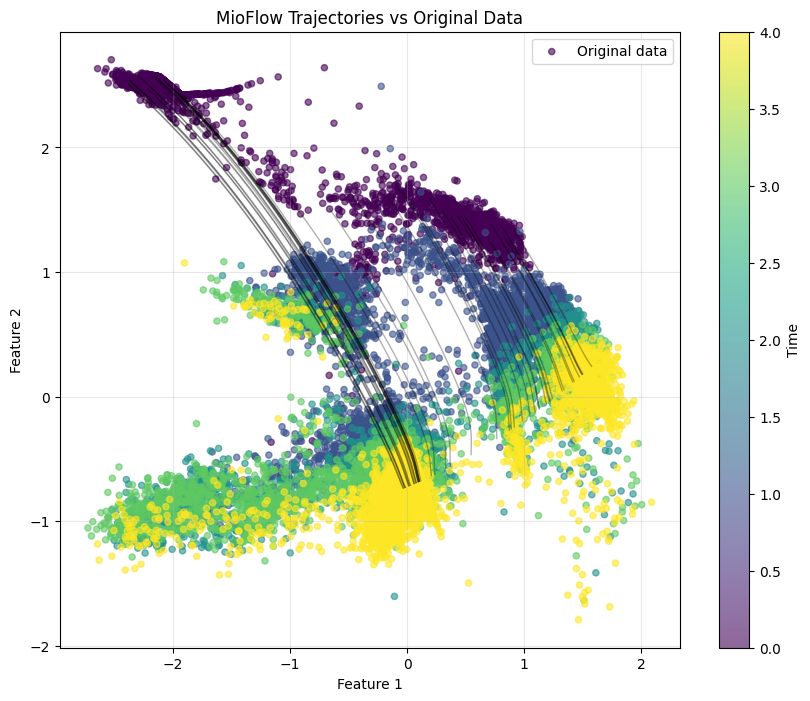

In [22]:
import matplotlib.pyplot as plt
import numpy as np

# Assuming 2D data - if higher dimensional, you might want to project first
# Get all original data points and their times
all_points = []
all_times = []
for i in range(len(mioflow_data.time_series_data)):
    points, time = mioflow_data.time_series_data[i]
    all_points.append(points)
    all_times.extend([time] * len(points))

all_points = np.vstack(all_points)  # [total_points, n_features]
all_times = np.array(all_times)     # [total_points]

# Create the plot
plt.figure(figsize=(10, 8))

# Plot original data points colored by time
scatter = plt.scatter(all_points[:, 0], all_points[:, 1],
                     c=all_times, cmap='viridis', alpha=0.6, s=20,
                     label='Original data')

# Plot trajectories as lines
for i in range(min(50, trajectories.size(0))):  # Plot first 50 trajectories to avoid clutter
    traj = trajectories[i].cpu().numpy()  # [100, n_features]
    plt.plot(traj[:, 0], traj[:, 1], 'k-', alpha=0.3, linewidth=1)

# Add colorbar
plt.colorbar(scatter, label='Time')

plt.title('MioFlow Trajectories vs Original Data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# Resources

Python Optimal Transport library: https://pythonot.github.io/index.html

Differentiable ODE solver library: https://github.com/rtqichen/torchdiffeq